In [1]:
import os
if os.path.basename(os.getcwd()) != "codes":
    os.chdir("codes")

import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from utils import model_performance

with open("../results/NaturalDesign/IVSN_res_myrun.pkl", "rb") as f:
    IVSN_res = pickle.load(f)
IVSN_accu = model_performance(IVSN_res, len(IVSN_res))
print(len(IVSN_res), len(IVSN_accu), IVSN_accu[:10])

240 100 [0, np.float64(0.1125), np.float64(0.24583333333333332), np.float64(0.35833333333333334), np.float64(0.44583333333333336), np.float64(0.5041666666666667), np.float64(0.5791666666666667), np.float64(0.6375), np.float64(0.6916666666666667), np.float64(0.7166666666666667)]


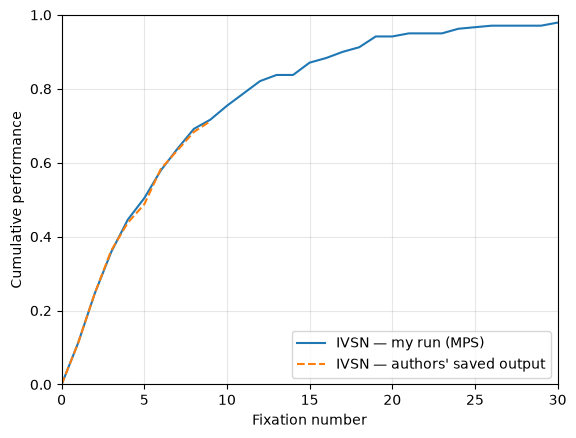

In [13]:
authors = [0, 0.1125, 0.24583333333333332, 0.3625, 0.4375, 0.4875,
           0.5833333333333334, 0.6333333333333333, 0.6833333333333333, 0.7125]

import matplotlib.pyplot as plt
plt.plot(range(len(IVSN_accu)), IVSN_accu, label="IVSN — my run (MPS)")
plt.plot(range(len(authors)), authors, "--", label="IVSN — authors' saved output")
plt.xlabel("Fixation number"); plt.ylabel("Cumulative performance")
plt.xlim(0, 30); plt.ylim(0, 1); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("../results/NaturalDesign/fig3b_model_myrun.png", dpi=200, bbox_inches="tight")
plt.show()

In [2]:
from scipy.io import loadmat
m = loadmat("dataset/naturaldesign/psy/naturaldesign.mat",
            squeeze_me=True, struct_as_record=False)
for k, v in m.items():
    if k.startswith("__"):
        continue
    print(k, type(v).__name__, getattr(v, "shape", ""))

MyData ndarray (480,)


In [3]:
from scipy.io import loadmat
m = loadmat("dataset/naturaldesign/psy/naturaldesign.mat", squeeze_me=True)

# MyData is the trial-to-image index, not fixation data: uint8 (480,).
# Entries 0-239 are the first presentations of images 1..240;
# entries 240-479 are the repeat presentations of the same images.
trial_image_id = m["MyData"]
print("trial_image_id:", trial_image_id.dtype, trial_image_id.shape)
print("first 10:", trial_image_id[:10])
print("last 10 :", trial_image_id[-10:])

trial_image_id: uint8 (480,)
first 10: [ 1  2  3  4  5  6  7  8  9 10]
last 10 : [231 232 233 234 235 236 237 238 239 240]


In [4]:
import glob
import numpy as np
from scipy.io import loadmat

files = sorted(glob.glob("dataset/naturaldesign/psy/ProcessScanpath_naturaldesign/*.mat"))
print("subjects:", len(files))
print([f.split("/")[-1] for f in files])

s  = loadmat(files[0], squeeze_me=True, struct_as_record=False)
fd = s["FixData"]

for f in fd._fieldnames:
    v = getattr(fd, f)
    print(f"  {f:16s} {type(v).__name__:12s} {getattr(v, 'shape', '')}")

tf = np.asarray(fd.TargetFound)
px = np.asarray(fd.Fix_posx)
print("\nTargetFound     :", tf.shape, tf[:20])
print("Fix_posx trial 0:", np.atleast_1d(px[0]))
print("fixation counts :", [len(np.atleast_1d(px[i])) for i in range(8)])
print("clickwrong      :", np.asarray(s["subjclickwrong"])[:20])

subjects: 31
['subj01-mm.mat', 'subj02-az.mat', 'subj02-az_oracle.mat', 'subj03-el.mat', 'subj03-el_oracle.mat', 'subj04-ni.mat', 'subj04-ni_oracle.mat', 'subj05-mi.mat', 'subj05-mi_oracle.mat', 'subj06-st.mat', 'subj06-st_oracle.mat', 'subj07-pl.mat', 'subj07-pl_oracle.mat', 'subj09-an.mat', 'subj09-an_oracle.mat', 'subj10-ni.mat', 'subj10-ni_oracle.mat', 'subj11-ta.mat', 'subj11-ta_oracle.mat', 'subj12-mi.mat', 'subj12-mi_oracle.mat', 'subj13-zw.mat', 'subj13-zw_oracle.mat', 'subj14-ji.mat', 'subj14-ji_oracle.mat', 'subj15-ra.mat', 'subj15-ra_oracle.mat', 'subj16-kr.mat', 'subj16-kr_oracle.mat', 'subj17-ke.mat', 'subj17-ke_oracle.mat']
  Fix_posx         ndarray      (480,)
  Fix_posy         ndarray      (480,)
  TargetFound      ndarray      (480, 65)
  Fix_time         ndarray      (480,)
  Fix_starttime    ndarray      (480,)
  Mouseclicktime   ndarray      (480,)

TargetFound     : (480, 65) [[0 1 0 ... 0 0 0]
 [0 0 1 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 1 0

In [1]:
# Is fixation 0 the central starting fixation? Image is 1280x1024, centre (640, 512).
import numpy as np
from scipy.io import loadmat

s  = loadmat("dataset/naturaldesign/psy/ProcessScanpath_naturaldesign/subj01-mm.mat",
             squeeze_me=True, struct_as_record=False)
fd = s["FixData"]
px = [np.atleast_1d(x) for x in fd.Fix_posx]
py = [np.atleast_1d(y) for y in fd.Fix_posy]
cx, cy = 640, 512

for k in (0, 1):
    xs = np.array([x[k] for x in px if len(x) > k], dtype=float)
    ys = np.array([y[k] for y in py if len(y) > k], dtype=float)
    dist = np.hypot(xs - cx, ys - cy)
    print(f"fixation {k}: n={len(xs)}")
    print(f"  x median {np.median(xs):7.1f}  std {xs.std():6.1f}   (centre {cx})")
    print(f"  y median {np.median(ys):7.1f}  std {ys.std():6.1f}   (centre {cy})")
    print(f"  distance from centre: median {np.median(dist):6.1f}  90th pct {np.percentile(dist, 90):6.1f}")

fixation 0: n=480
  x median   645.0  std   11.5   (centre 640)
  y median   514.0  std   15.2   (centre 512)
  distance from centre: median   16.0  90th pct   27.9
fixation 1: n=480
  x median   743.0  std  192.7   (centre 640)
  y median   514.0  std  120.4   (centre 512)
  distance from centre: median  194.6  90th pct  369.7


In [1]:
# SUPERSEDED - DO NOT USE. FixData trials are in presentation order (see CHECK 1),
# so [:240] is a random mix of first and repeat views, not first presentations.
# The numbers below are wrong; CHECK 2 has the corrected selection rules.
# Human fixations-to-find on natural design, under both centre conventions.
import glob, os
import numpy as np
from scipy.io import loadmat

subj_files = sorted(f for f in glob.glob("dataset/naturaldesign/psy/ProcessScanpath_naturaldesign/*.mat")
                    if "_oracle" not in os.path.basename(f))

pooled, per_subj_excl, per_subj_incl = [], [], []
n_kept = n_dropped = n_never = 0
for f in subj_files:
    s  = loadmat(f, squeeze_me=True, struct_as_record=False)
    tf = np.asarray(s["FixData"].TargetFound)[:240]       # first presentations only
    cw = np.asarray(s["subjclickwrong"], dtype=float)[:240]

    keep = cw == 0                                         # drops clickwrong == 1 and NaN
    n_dropped += int((~keep).sum())
    n_kept    += int(keep.sum())

    tf = tf[keep]
    found = tf.sum(axis=1) == 1
    n_never += int((tf.sum(axis=1) == 0).sum())
    assert (tf.sum(axis=1) <= 1).all(), f"multiple 1s in TargetFound row: {f}"

    cols = tf[found].argmax(axis=1)
    pooled.append(cols)
    per_subj_excl.append(cols.mean())
    per_subj_incl.append((cols + 1).mean())

cols = np.concatenate(pooled)
print("subjects          :", len(subj_files))
print("trials kept       :", n_kept)
print("trials dropped    :", n_dropped, "(clickwrong 1 or NaN)")
print("trials never found:", n_never, "(of the kept trials)")
print()
print(f"pooled, centre excluded (col)     : mean {cols.mean():.3f}  std {cols.std():.3f}")
print(f"pooled, centre included (col + 1) : mean {(cols + 1).mean():.3f}  std {(cols + 1).std():.3f}")
print(f"per-subject, centre excluded      : mean {np.mean(per_subj_excl):.3f}  std across subjects {np.std(per_subj_excl):.3f}")
print(f"per-subject, centre included      : mean {np.mean(per_subj_incl):.3f}  std across subjects {np.std(per_subj_incl):.3f}")

subjects          : 16
trials kept       : 2868
trials dropped    : 972 (clickwrong 1 or NaN)
trials never found: 0 (of the kept trials)

pooled, centre excluded (col)     : mean 7.154  std 8.779
pooled, centre included (col + 1) : mean 8.154  std 8.779
per-subject, centre excluded      : mean 7.179  std across subjects 1.102
per-subject, centre included      : mean 8.179  std across subjects 1.102


In [2]:
# CHECK 1 - are FixData's 480 trials in image order (1..240, 1..240) or presentation order?
# The subject .mat files hold only FixData and subjclickwrong - no image-id or sequence field.
# MMScanpathPreprocess_subj01.m reads trials in run order (TRIAL_ON: <trial>) and loads the
# image as MyData(seq(trial)), with seq from naturaldesign_seq.mat. Test both orderings.
import numpy as np
from PIL import Image
from scipy.io import loadmat

psy = "dataset/naturaldesign/psy/"
MyData = loadmat(psy + "naturaldesign.mat", squeeze_me=True)["MyData"].astype(int)
seq    = loadmat(psy + "naturaldesign_seq.mat", squeeze_me=True)["seq"].astype(int)
print("seq:", seq.shape, "permutation of 1..480:", sorted(seq) == list(range(1, 481)))

img_image_order = MyData                 # trial t shows image MyData[t]
img_presentation = MyData[seq - 1]       # trial t shows image MyData(seq(t))

# target centre (x, y) per image from the ground-truth masks (1280x1024, same as screen)
tgt = {}
for n in range(1, 241):
    g = np.asarray(Image.open(f"dataset/naturaldesign/gt/gt{n}.jpg").convert("L"))
    ys, xs = np.nonzero(g > 127)
    tgt[n] = (xs.mean(), ys.mean())

def pairs(img_of_trial):
    first, out = {}, []
    for t, n in enumerate(img_of_trial):
        if n in first: out.append((first[n], t))
        else: first[n] = t
    return out

for name in ("subj01-mm", "subj02-az"):
    s  = loadmat(psy + f"ProcessScanpath_naturaldesign/{name}.mat", squeeze_me=True, struct_as_record=False)
    fd = s["FixData"]
    px = [np.atleast_1d(x).astype(float) for x in fd.Fix_posx]
    py = [np.atleast_1d(y).astype(float) for y in fd.Fix_posy]
    tf = np.asarray(fd.TargetFound)
    found = tf.sum(axis=1) == 1
    col = tf.argmax(axis=1)
    print(f"\n{name}")
    for label, img in (("image order (i / i+240)", img_image_order),
                       ("presentation order (seq)", img_presentation)):
        # (a) fixation at which the target was found vs that image's target centre
        d = [np.hypot(px[t][col[t]] - tgt[img[t]][0], py[t][col[t]] - tgt[img[t]][1])
             for t in range(480) if found[t] and col[t] < len(px[t])]
        # (b) final fixations of the two trials showing the same image
        pr = [(a, b) for a, b in pairs(img) if found[a] and found[b]]
        ax = np.array([px[a][-1] for a, b in pr]); bx = np.array([px[b][-1] for a, b in pr])
        ay = np.array([py[a][-1] for a, b in pr]); by = np.array([py[b][-1] for a, b in pr])
        print(f"  {label:26s} found-fixation to target: median {np.median(d):6.1f} px, "
              f"within 100 px {np.mean(np.array(d) < 100):5.1%} | "
              f"final-fixation pairs n={len(pr)}: r_x {np.corrcoef(ax, bx)[0,1]:+.3f}  "
              f"r_y {np.corrcoef(ay, by)[0,1]:+.3f}  median dist {np.median(np.hypot(ax-bx, ay-by)):6.1f} px")

seq: (480,) permutation of 1..480: True



subj01-mm
  image order (i / i+240)    found-fixation to target: median  497.3 px, within 100 px  3.1% | final-fixation pairs n=238: r_x +0.039  r_y -0.036  median dist  484.6 px
  presentation order (seq)   found-fixation to target: median   74.5 px, within 100 px 65.5% | final-fixation pairs n=239: r_x +0.988  r_y +0.976  median dist   34.1 px

subj02-az
  image order (i / i+240)    found-fixation to target: median  500.5 px, within 100 px  4.3% | final-fixation pairs n=200: r_x -0.012  r_y -0.046  median dist  519.5 px
  presentation order (seq)   found-fixation to target: median   86.3 px, within 100 px 58.0% | final-fixation pairs n=211: r_x +0.943  r_y +0.939  median dist   57.3 px


In [3]:
# CHECK 2 - human mean fixations-to-find (centre excluded = TargetFound column index)
# under four trial-selection rules. "First presentation" = the earlier of the two trials
# that show each image, using the presentation-order mapping img_presentation from CHECK 1.
import glob, os

first_pres = np.zeros(480, dtype=bool)
seen = set()
for t, n in enumerate(img_presentation):
    if n not in seen:
        first_pres[t] = True
        seen.add(n)

subj_files = sorted(f for f in glob.glob(psy + "ProcessScanpath_naturaldesign/*.mat")
                    if "_oracle" not in os.path.basename(f))
rules = {"A  first pres, drop wrong+NaN": (True,  True),
         "B  all 480,    drop wrong+NaN": (False, True),
         "C  first pres, drop NaN only ": (True,  False),
         "D  all 480,    drop NaN only ": (False, False)}
cols = {r: [] for r in rules}
pct_wrong, pct_nan = [], []
for f in subj_files:
    s  = loadmat(f, squeeze_me=True, struct_as_record=False)
    tf = np.asarray(s["FixData"].TargetFound)
    cw = np.asarray(s["subjclickwrong"], dtype=float)
    assert ((tf.sum(axis=1) == 0) == np.isnan(cw)).all()   # NaN <=> target never found
    pct_wrong.append(100 * np.mean(cw == 1))
    pct_nan.append(100 * np.mean(np.isnan(cw)))
    for r, (first_only, drop_wrong) in rules.items():
        keep = ~np.isnan(cw)
        if drop_wrong: keep &= cw == 0
        if first_only: keep &= first_pres
        cols[r].append(tf[keep].argmax(axis=1))

print(f"{'rule':32s} {'pooled mean':>11s} {'pooled std':>10s} {'subj mean':>9s} {'subj std':>8s}  n")
for r in rules:
    pooled = np.concatenate(cols[r]); per = [c.mean() for c in cols[r]]
    print(f"{r:32s} {pooled.mean():11.3f} {pooled.std():10.3f} {np.mean(per):9.3f} {np.std(per):8.3f}  {len(pooled)}")

print(f"\n{'subject':12s} {'% clickwrong==1':>15s} {'% NaN (never found)':>20s}   (of all 480 trials)")
for f, w, n in zip(subj_files, pct_wrong, pct_nan):
    print(f"{os.path.basename(f)[:-4]:12s} {w:15.1f} {n:20.1f}")
print(f"{'mean +/- sd':12s} {np.mean(pct_wrong):8.1f} +/- {np.std(pct_wrong):3.1f} {np.mean(pct_nan):13.1f} +/- {np.std(pct_nan):3.1f}")
both = np.array(pct_wrong) + np.array(pct_nan)
print(f"{'wrong + NaN':12s} {np.mean(both):8.1f} +/- {np.std(both):3.1f}")

rule                             pooled mean pooled std subj mean subj std  n
A  first pres, drop wrong+NaN          8.416      9.435     8.452    1.225  2712
B  all 480,    drop wrong+NaN          5.984      7.825     6.013    0.842  5897
C  first pres, drop NaN only          11.480     12.621    11.544    1.815  3355
D  all 480,    drop NaN only           8.295     11.040     8.335    1.431  6951

subject      % clickwrong==1  % NaN (never found)   (of all 480 trials)
subj01-mm                4.6                  0.4
subj02-az                7.7                  8.3
subj03-el                8.1                  6.9
subj04-ni               17.5                  7.1
subj05-mi               14.2                  8.8
subj06-st               18.1                  8.5
subj07-pl               20.8                 10.0
subj09-an               21.5                  8.5
subj10-ni               14.0                  9.4
subj11-ta                9.2                 12.1
subj12-mi               1

subjects: 16 | trials found on fixation 0 (dropped by 2:end): 210
  fixation  1: 0.1307
  fixation  2: 0.2874
  fixation  3: 0.4016
  fixation  5: 0.5366
  fixation 10: 0.6719
  fixation 20: 0.7719
  fixation 30: 0.8194
asymptote 0.8777  ->  failure rate 12.2%  (paper 16.4 +/- 5.9%)
across subjects: asymptote 0.8777 +/- 0.0375, failure 12.2 +/- 3.8%


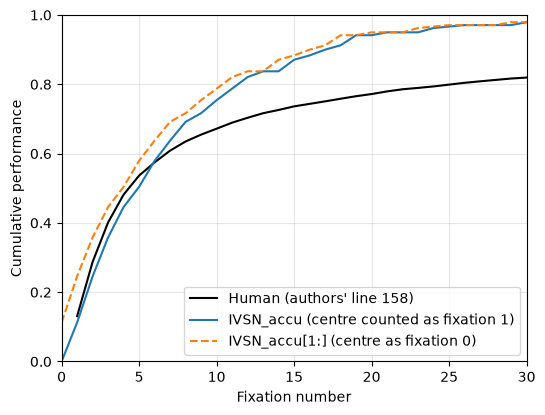


 fix   human   IVSN_accu  IVSN_accu[1:]
   1  0.1307   0.1125     0.2458
   2  0.2874   0.2458     0.3583
   3  0.4016   0.3583     0.4458
   5  0.5366   0.5042     0.5792
  10  0.6719   0.7542     0.7875
  20  0.7719   0.9417     0.9500
  30  0.8194   0.9792     0.9792


In [4]:
# Authors' human curve, MMScanpathPreprocess_subj01.m line 158:
#     plot(cumsum(nanmean(TargetFound(:,2:end,1))))
# Column 1 (fixation 0, the centre) dropped; mean over all 480 trials, no exclusions;
# never-found rows are all zero and stay in. human_accu[j] = P(found by fixation j+1).
subj_files = sorted(f for f in glob.glob(psy + "ProcessScanpath_naturaldesign/*.mat")
                    if "_oracle" not in os.path.basename(f))
curves, found_at_centre = [], 0
for f in subj_files:
    tf = np.asarray(loadmat(f, squeeze_me=True, struct_as_record=False)["FixData"].TargetFound, dtype=float)
    found_at_centre += int(tf[:, 0].sum())
    curves.append(np.cumsum(np.nanmean(tf[:, 1:], axis=0)))

# TargetFound widths differ by subject (64-80 columns); a cumulative curve is flat
# past its last column, so pad each with its final value
L = max(len(c) for c in curves)
curves = np.array([np.pad(c, (0, L - len(c)), mode="edge") for c in curves])
human_accu = curves.mean(axis=0)

print("subjects:", len(subj_files), "| trials found on fixation 0 (dropped by 2:end):", found_at_centre)
for n in (1, 2, 3, 5, 10, 20, 30):
    print(f"  fixation {n:2d}: {human_accu[n - 1]:.4f}")
asym = curves[:, -1]
print(f"asymptote {human_accu[-1]:.4f}  ->  failure rate {100 * (1 - human_accu[-1]):.1f}%  (paper 16.4 +/- 5.9%)")
print(f"across subjects: asymptote {asym.mean():.4f} +/- {asym.std():.4f}, "
      f"failure {100 * (1 - asym).mean():.1f} +/- {100 * (1 - asym).std():.1f}%")

accu = np.asarray(IVSN_accu, dtype=float)
plt.figure(figsize=(6, 4.5))
plt.plot(np.arange(1, L + 1), human_accu, "k-", label="Human (authors' line 158)")
plt.plot(np.arange(len(accu)), accu, "C0-", label="IVSN_accu (centre counted as fixation 1)")
plt.plot(np.arange(len(accu) - 1), accu[1:], "C1--", label="IVSN_accu[1:] (centre as fixation 0)")
plt.xlabel("Fixation number"); plt.ylabel("Cumulative performance")
plt.xlim(0, 30); plt.ylim(0, 1); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.savefig("../results/NaturalDesign/fig3b_three_curves.png", dpi=200, bbox_inches="tight")
plt.show()

print("\n fix   human   IVSN_accu  IVSN_accu[1:]")
for n in (1, 2, 3, 5, 10, 20, 30):
    print(f" {n:3d}  {human_accu[n - 1]:.4f}   {accu[n]:.4f}     {accu[n + 1]:.4f}")